# HomiQ: Bengaluru House Price Prediction

This notebook uses the CC0 Bengaluru House Price Data dataset. Linear Regression trains and evaluates against the original INR target; monetary values shown in EDA, charts, and metrics are converted to USD for display. The project is Bengaluru-specific, not a pan-India valuation model.

## 1. Imports and reproducibility

Install dependencies with `pip install -r requirements.txt` from the project root. The first data load requires internet access; the CC0 Kaggle data is cached under `data/raw/`. The latest available daily INR/USD rate is fetched for display, with a configurable fallback.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "homiq").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from homiq.currency import get_exchange_rate
from homiq.data import TARGET, describe_dataset, iqr_outlier_counts, load_indian_housing
from homiq.modeling import (
    BASELINE_NUMERIC_FEATURES,
    IMPROVED_CATEGORICAL_FEATURES,
    IMPROVED_FEATURES,
    IMPROVED_NUMERIC_FEATURES,
    build_pipeline,
    cross_validation_summary,
    evaluate_regression,
    validate_feature_columns,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
exchange_rate = get_exchange_rate()
print(f"Display rate: 1 INR = ${exchange_rate.usd_per_inr:.5f} ({exchange_rate.source}, {exchange_rate.rate_date})")
if exchange_rate.error:
    print("Live rate unavailable; using the configured fallback.")

Display rate: 1 INR = $0.01067 (Frankfurter, 2026-11-11)


## 2. Load the data and inspect its quality

The source price is recorded in lakh rupees. The loader converts it to the model target in INR, standardizes area to square feet, and extracts bedroom/BHK counts. Exact duplicates are removed; invalid target/area/size records are excluded. IQR outliers are reported, not automatically deleted.

In [2]:
df = load_indian_housing()
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {duplicate_count:,}")
describe_dataset(df, exchange_rate.usd_per_inr)
print("\nIQR outlier counts (not automatically removed):")
display(iqr_outlier_counts(df).head(15))
print(f"\nUnique Bengaluru localities: {df['location'].nunique():,}")

Duplicate rows removed: 692
Dataset shape: (12598, 7)

Columns:
['area_type', 'location', 'bhk', 'total_sqft', 'bath', 'balcony', 'price_inr']

Data types:
area_type     string[python]
location      string[python]
bhk                  float64
total_sqft           float64
bath                 float64
balcony              float64
price_inr            float64

Numeric summary (prices in USD):
                  count           mean            std     min      25%        50%        75%        max
bhk             12598.0       2.825131       1.316651     1.0      2.0      3.000       3.00       43.0
total_sqft      12598.0    1945.614106   17764.112859     1.0   1100.0   1286.000    1699.75  1306800.0
bath            12542.0       2.715675       1.363053     1.0      2.0      2.000       3.00       40.0
balcony         12011.0       1.585547       0.824422     0.0      1.0      2.000       2.00        3.0
ListedPriceUSD  12598.0  122743.338230  162576.984381  8538.4  53365.0  78307.801  1312

price_inr     1207
total_sqft    1151
bath          1029
bhk            839
balcony          0
dtype: int64


Unique Bengaluru localities: 1,293


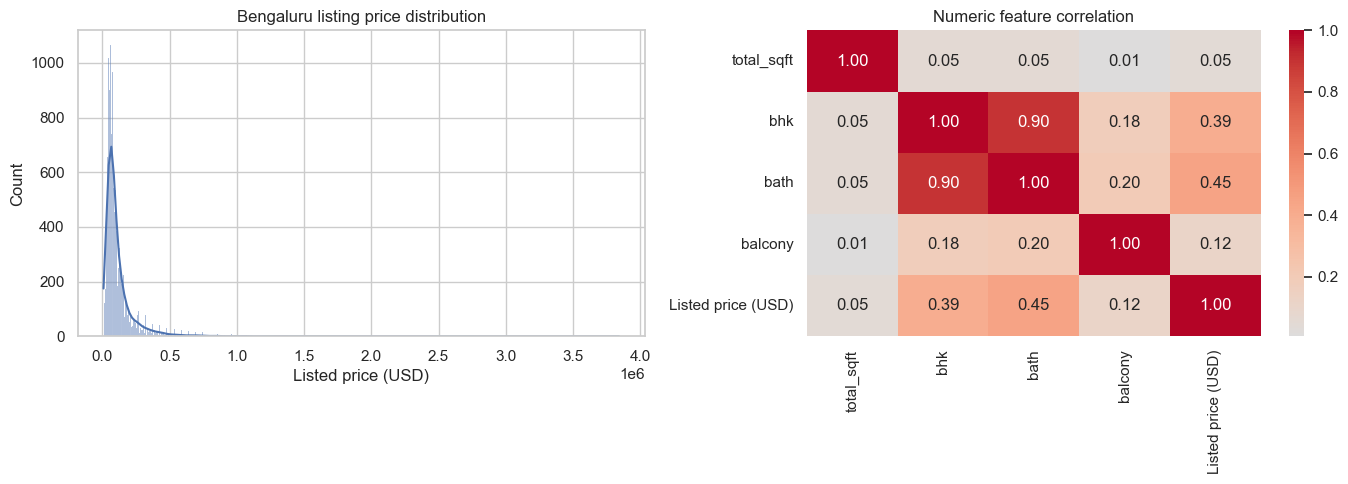

In [3]:
price_usd = df[TARGET] * exchange_rate.usd_per_inr
correlation_cols = [*IMPROVED_NUMERIC_FEATURES, TARGET]
correlation = df[correlation_cols].corr(numeric_only=True)
correlation = correlation.rename(columns={TARGET: "Listed price (USD)"})
correlation = correlation.rename(index={TARGET: "Listed price (USD)"})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price_usd, kde=True, ax=axes[0])
axes[0].set(title="Bengaluru listing price distribution", xlabel="Listed price (USD)")
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Numeric feature correlation")
plt.tight_layout()

## 3. Define features and split before fitting preprocessing

The baseline uses area, BHK/bedroom count, and bathrooms. The richer model adds balconies, Bengaluru locality, and area type. We reserve 20% for one final test; imputers, scaling, and one-hot encoding are fit inside cross-validation folds and never learn from held-out rows.

In [4]:
validate_feature_columns(df, IMPROVED_FEATURES)
X = df[IMPROVED_FEATURES].copy()
y = df[TARGET].copy()  # INR values remain the model target.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}; holdout test: {X_test.shape}")

Train: (10078, 6); holdout test: (2520, 6)


## 4. Preprocess and compare linear regression models

The numeric branch median-imputes and standardizes. The categorical branch uses the training-fold mode and one-hot encoding with infrequent locality grouping. We select between the predeclared feature sets using mean five-fold training R², then use the holdout once.

In [5]:
baseline = build_pipeline(BASELINE_NUMERIC_FEATURES)
improved = build_pipeline(IMPROVED_NUMERIC_FEATURES, IMPROVED_CATEGORICAL_FEATURES)
baseline_cv = cross_validation_summary(baseline, X_train[BASELINE_NUMERIC_FEATURES], y_train)
improved_cv = cross_validation_summary(improved, X_train, y_train)

comparison = pd.DataFrame([baseline_cv, improved_cv], index=["Baseline", "Richer features"])
comparison_display = comparison.copy()
comparison_display[["rmse", "mae"]] *= exchange_rate.usd_per_inr
comparison_display = comparison_display.rename(columns={"rmse": "RMSE (USD)", "mae": "MAE (USD)", "r2": "R²"})
display(comparison_display)

use_improved = improved_cv["r2"] > baseline_cv["r2"]
selected_model = improved if use_improved else baseline
selected_features = IMPROVED_FEATURES if use_improved else BASELINE_NUMERIC_FEATURES
selected_model.fit(X_train[selected_features], y_train)
predictions_inr = selected_model.predict(X_test[selected_features])
test_metrics_inr = evaluate_regression(y_test, predictions_inr)
test_metrics_usd = {
    "MSE (USD²)": test_metrics_inr["mse"] * exchange_rate.usd_per_inr**2,
    "RMSE (USD)": test_metrics_inr["rmse"] * exchange_rate.usd_per_inr,
    "MAE (USD)": test_metrics_inr["mae"] * exchange_rate.usd_per_inr,
    "R²": test_metrics_inr["r2"],
}
print("Selected model:", "richer features" if use_improved else "baseline")
display(pd.Series(test_metrics_usd, name="Held-out test metrics"))

,RMSE (USD),MAE (USD),R²
Baseline,146228.073957,62149.822981,0.193414
Richer features,140905.858160,59927.326087,0.251774


Selected model: richer features


MSE (USD²)    1.802460e+10
RMSE (USD)    1.342557e+05
MAE (USD)     5.934625e+04
R²            2.594443e-01
Name: Held-out test metrics, dtype: float64

## 5. Evaluate and interpret the plots

- **MSE** is the average squared error; the notebook converts it to USD² for display.
- **RMSE** is the square root of MSE and is displayed in USD.
- **MAE** is the average absolute miss and is displayed in USD.
- **R²** is unitless and measures variance explained relative to predicting the test-set mean; it can be negative.

The actual/predicted chart includes an ideal diagonal; residuals are actual minus predicted. A residual pattern or widening spread can indicate nonlinearity or unequal error variance. No confidence interval is shown because this model has not been calibrated for uncertainty.

bath          0.451588
bhk           0.393603
balcony       0.116421
total_sqft    0.048298
Name: price_inr, dtype: float64

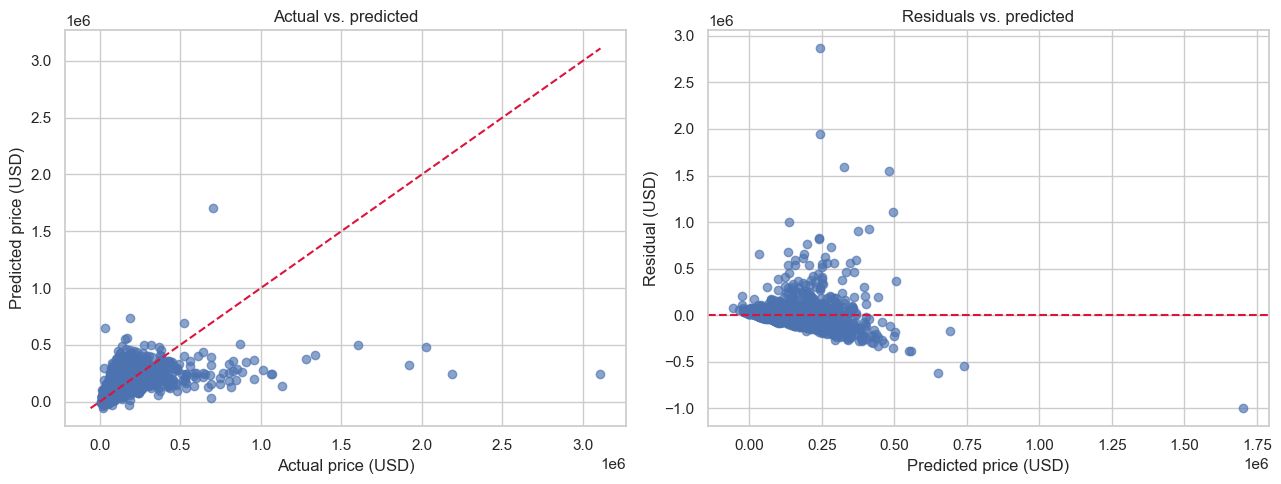

In [6]:
actual_usd = y_test.to_numpy() * exchange_rate.usd_per_inr
predicted_usd = predictions_inr * exchange_rate.usd_per_inr
residuals_usd = actual_usd - predicted_usd
limits = [min(actual_usd.min(), predicted_usd.min()), max(actual_usd.max(), predicted_usd.max())]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual_usd, predicted_usd, alpha=0.65)
axes[0].plot(limits, limits, "--", color="crimson")
axes[0].set(title="Actual vs. predicted", xlabel="Actual price (USD)", ylabel="Predicted price (USD)")
axes[1].scatter(predicted_usd, residuals_usd, alpha=0.65)
axes[1].axhline(0, color="crimson", linestyle="--")
axes[1].set(title="Residuals vs. predicted", xlabel="Predicted price (USD)", ylabel="Residual (USD)")
plt.tight_layout()

numeric_correlations = df[IMPROVED_NUMERIC_FEATURES + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET)
display(numeric_correlations.reindex(numeric_correlations.abs().sort_values(ascending=False).index).head(10))

## 6. Reproduce the deployable model and visual reports

Run `python train.py` from the project root to perform this workflow end-to-end, save `models/linear_regression.joblib`, write INR evaluation metrics to `reports/metrics.json`, and generate USD price visualizations. The Streamlit app fetches the latest available rate for presentation and never retrains on page visits.